<a href="https://colab.research.google.com/github/Prateek-Dhar-Dwivedi/AML_Practical_2026_IPYNB_Files-/blob/main/raw_house_dataset_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##ASK SIR WHEN I SCALED THE SELLING PRICE THAN VALIDATION AND TRAING LESS IS LOW BUT WHEN NOT LOSS INCREASES VERY MUCH!!!

In [ ]:
#Documetaion https://docs.google.com/document/d/1YHRXQZaL0zuYYuWZZ6INYIaim7vc6GXKMh-fBOGagMw/edit?usp=sharing
#Excel Sheet Link : https://docs.google.com/spreadsheets/d/1Da48Y7s9IR3KjIIDfuABWjt8VVP3TsT9hi3htsYpHUw/edit?usp=sharing
#Colab file when OwnerName is taken as feature : https://colab.research.google.com/drive/1hq0AJN8Js9hueN-TG6OcyTsR5XiE9Ilf?usp=sharing

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# =====================================================
# STEP 1 : LOAD DATA
# =====================================================

df = pd.read_excel("raw_house_dataset.xlsx")

print("\nColumns in Dataset:\n")
print(df.columns.tolist())


Columns in Dataset:

['Area_sqft', 'ElectricityBill', 'SellingPrice', 'DistanceToCity', 'Green', 'Blue', 'Red', 'Grey', 'Garage', 'Garden', 'NearSchool', 'Bedrooms', 'Bathrooms', 'Facing_West', 'Facing_North', 'Facing_South', 'Facing_East', 'Age']


##MANUALLY COMPLETED STEP 2

In [ ]:
# =====================================================
# STEP 2 : SPECIFY IRRELEVANT COLUMNS
#
# Students should modify this list.
# Remove only those columns which are not useful.
# =====================================================

# features_to_remove = [ "ID", "OwnerName" ]

# # Delete specified columns
# df = df.drop(columns=features_to_remove)



In [ ]:
# =====================================================
# STEP 3 : DEFINE INPUTS AND OUTPUT
# =====================================================

target = "SellingPrice"

X = df.drop(columns=[target])
y = df[target]

print("\nFeatures Used:")
print(X.columns.tolist())


Features Used:
['Area_sqft', 'ElectricityBill', 'DistanceToCity', 'Green', 'Blue', 'Red', 'Grey', 'Garage', 'Garden', 'NearSchool', 'Bedrooms', 'Bathrooms', 'Facing_West', 'Facing_North', 'Facing_South', 'Facing_East', 'Age']


In [ ]:
# =====================================================
# STEP 4 : SPLIT DATA
# =====================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

In [ ]:
# =====================================================
# STEP 5 : NORMALIZATION
# =====================================================

scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [ ]:
# =====================================================
# STEP 6 : CREATE NEURAL NETWORK
# =====================================================

model = MLPRegressor(
    hidden_layer_sizes=(16,8),
    activation='relu',
    solver='adam',
    max_iter=1,
    warm_start=True,
    random_state=10
)

epochs = 200

training_loss = []
validation_loss = []

In [ ]:
# =====================================================
# STEP 7 : TRAINING
# =====================================================

for epoch in range(epochs):

    model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    val_prediction = model.predict(X_val)

    train_mse = mean_squared_error(y_train, train_prediction)
    val_mse = mean_squared_error(y_val, val_prediction)

    training_loss.append(train_mse)
    validation_loss.append(val_mse)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691

In [ ]:
# =====================================================
# STEP 8 : TESTING
# =====================================================

test_prediction = model.predict(X_test)

test_mse = mean_squared_error(y_test, test_prediction)
test_r2 = r2_score(y_test, test_prediction)

print("\n==============================")
print("Testing Results")
print("==============================")

print("Test MSE :", round(test_mse,2))
print("R² Score :", round(test_r2,4))


Testing Results
Test MSE : 0.02
R² Score : 0.7729


In [ ]:
# =====================================================
# STEP 9 : SAMPLE PREDICTIONS
# =====================================================

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": test_prediction
})

print("\nSample Predictions\n")
print(results.head(10))



Sample Predictions

   Actual Price  Predicted Price
0      0.645754         0.648312
1      0.780422         0.817076
2      0.176852         0.369219
3      0.954029         0.842244
4      0.704705         0.749704
5      0.091942         0.232544
6      0.412115         0.383532
7      0.267171         0.300218
8      0.374797         0.544592
9      0.484586         0.380874


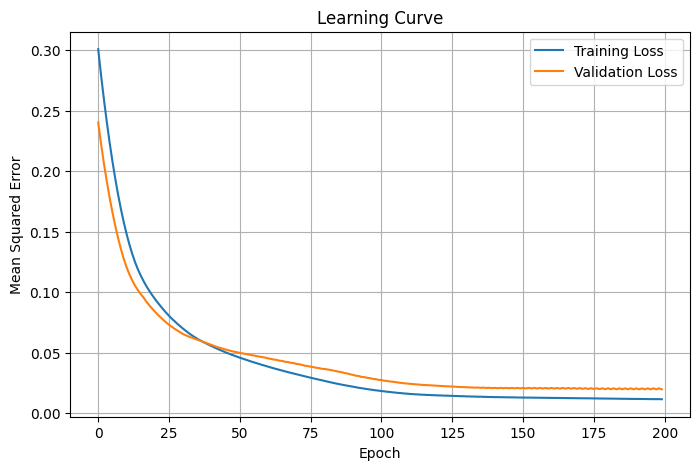

In [ ]:
# =====================================================
# STEP 10 : LEARNING CURVE
# =====================================================

plt.figure(figsize=(8,5))

plt.plot(training_loss,label="Training Loss")
plt.plot(validation_loss,label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)

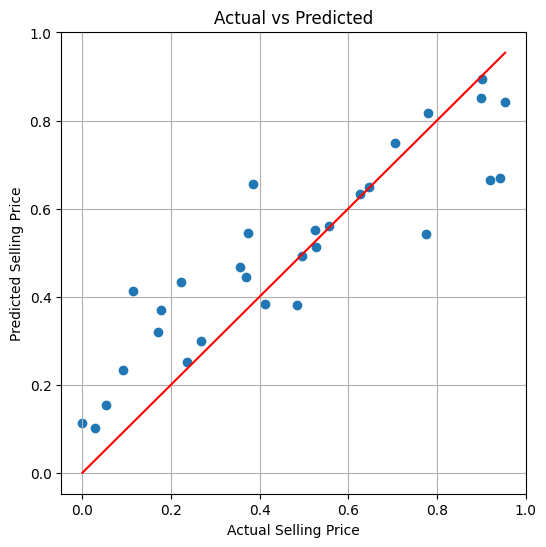

In [ ]:
# =====================================================
# STEP 11 : ACTUAL vs PREDICTED
# =====================================================

plt.figure(figsize=(6,6))

plt.scatter(y_test,test_prediction)

minimum=min(min(y_test),min(test_prediction))
maximum=max(max(y_test),max(test_prediction))

plt.plot([minimum,maximum],[minimum,maximum],'r')

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted")
plt.grid(True)

plt.show()